# Create a Simple Reflex-Based Lunar Lander Agent

In this example, we will use Gymnasium, an environment to train agents via reinforcement learning (RL). We will not use RL here but just use the environment with a custom simple reflex-based agent. 

## Install Gymnasium

The documentation for Gymnasium is available at https://gymnasium.farama.org/ 

Steps:
1. Create a new folder and open it with VS Code and install all needed Python Extensions in VS Code.
2. Create a new virtual environment (CTRL-Shift P Python Create Environment...)
3. I needed to install swig and the Python C++ headers on WSL2 via the terminal
    * `sudo apt install swig`
    * `sudo apt-get install python3-dev` 
4. Install python libraries for gymnasium with the needed extras

In [3]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "swig>=4,<5" "gymnasium[box2d,classic-control]>=1.0,<2"

Additional installs for screen capturing so environment visualizations can be converted to embedded videos.
For recording videos, I had to install
    
* `sudo apt-get install xvfb ffmpeg`

Additional python packages for screen capturing.

In [4]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "pyvirtualdisplay>=3,<4" "gymnasium[other]>=1.0,<2"

## The Lunar Lander Environment 

![Luna Lander image](https://gymnasium.farama.org/_images/lunar_lander.gif)

The documentation of the environment is available at: https://gymnasium.farama.org/environments/box2d/lunar_lander/

* Performance Measure: A reward of -100 or +100 points for crashing or landing safely respectively. We do not use 
  intermediate rewards here.

* Environment: This environment is a classic rocket trajectory optimization problem. A ship needs to land safely. The space is **continuous** with
  x and y coordinates in the range [-2.5, 2.5]. The landing pad is at coordinate (0,0).

* Actuators:  According to Pontryagin’s
  maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off. There are four discrete actions available:

    - 0: do nothing
    - 1: fire left orientation engine
    - 2: fire main engine
    - 3: fire right orientation engine

* Sensors: Each observation is an 8-dimensional vector: the coordinates of the lander in x & y, its linear velocities in x & y, its angle, its angular velocity, and two booleans that represent whether each leg is in contact with the ground or not.

The different ranges/settings of the environment can be queried.

In [5]:
import gymnasium as gym
import numpy as np
np.set_printoptions(precision=2)

In [6]:
def query_environment(name):
    env = gym.make(name)
    print(f"Action Space: {env.action_space}")
    print(f"Observation Space: {env.observation_space}")
    print(f"Max Episode Steps: {env.spec.max_episode_steps}")
    print(f"Nondeterministic: {env.spec.nondeterministic}")
   # print(f"Reward Range: {env.reward_range}")
    print(f"Reward Threshold: {env.spec.reward_threshold}")
    env.close()

query_environment("LunarLander-v3")

Action Space: Discrete(4)
Observation Space: Box([ -2.5   -2.5  -10.   -10.    -6.28 -10.    -0.    -0.  ], [ 2.5   2.5  10.   10.    6.28 10.    1.    1.  ], (8,), float32)
Max Episode Steps: 1000
Nondeterministic: False
Reward Threshold: 200



Gymnasium environments are implemented as classes with a `make` method to create the environment, a `reset` method, and a `step` method to execute an action.
To use it with an agent function that expects percepts and returns an action, we need write glue code that connects the environment with the agent function.

In [7]:
def run_episode(agent_function, env, max_steps=1000, verbose = True, render = True):
    """Run one episode in the environment using the provided agent."""

    # Reset the environment to generate the first observation (use seed=42 in reset to get reproducible results)
    observation, info = env.reset()

    # run one episode
    for _ in range(max_steps):
        # call the agent function to select an action
        action = agent_function(observation)

        if verbose:
            print (f"Obs: {observation} -> Action: {action}")

        # step: execute an action in the environment
        observation, reward, terminated, truncated, info = env.step(action)

        # render the environment
        if render:
            env.render()

        if terminated:
            if verbose:
                print(f"Final Reward: {reward}")
            break
    
    return reward

## Example: A Random Agent

We randomly return one of the actions. The environment accepts the integers 0-3.


In [8]:
def random_agent_function(observation): 
    """A random agent that selects actions uniformly at random. It ignores the observation."""
    return np.random.choice([0, 1, 2, 3], p=[0.25, 0.25, 0.25, 0.25])

Run an episode.

In [9]:
env = gym.make("LunarLander-v3", render_mode="human")

run_episode(random_agent_function, env)

env.close()

Obs: [-3.46e-04  1.40e+00 -3.51e-02 -4.18e-01  4.08e-04  7.95e-03  0.00e+00
  0.00e+00] -> Action: 0
Obs: [-6.93e-04  1.39e+00 -3.50e-02 -4.44e-01  8.01e-04  7.85e-03  0.00e+00
  0.00e+00] -> Action: 1
Obs: [-1.11e-03  1.38e+00 -4.41e-02 -4.70e-01  3.01e-03  4.41e-02  0.00e+00
  0.00e+00] -> Action: 0
Obs: [-0.    1.37 -0.04 -0.5   0.01  0.04  0.    0.  ] -> Action: 3
Obs: [-0.    1.36 -0.03 -0.52  0.01  0.    0.    0.  ] -> Action: 2
Obs: [-0.    1.35 -0.03 -0.48  0.01  0.01  0.    0.  ] -> Action: 3
Obs: [-0.    1.34 -0.02 -0.51  0.   -0.03  0.    0.  ] -> Action: 3
Obs: [-2.52e-03  1.32e+00 -1.15e-02 -5.38e-01  1.25e-03 -6.30e-02  0.00e+00
  0.00e+00] -> Action: 3
Obs: [-0.    1.31 -0.   -0.56 -0.   -0.1   0.    0.  ] -> Action: 3
Obs: [-0.    1.3   0.01 -0.59 -0.01 -0.14  0.    0.  ] -> Action: 1
Obs: [-2.66e-03  1.28e+00 -1.04e-03 -6.18e-01 -1.56e-02 -1.05e-01  0.00e+00
  0.00e+00] -> Action: 0
Obs: [-2.73e-03  1.27e+00 -1.03e-03 -6.45e-01 -2.08e-02 -1.05e-01  0.00e+00
  0.00e+00]

Gymnasium displays environments using `render()` method on the local display. Headless installations like Google Colab do not have a display, but the output can be captured using a virtual display as a video and then add the video to the notebook.

We need to start a virtual display.

Now we can use wrappers for the environment to record the display. The functions are provided in
[display_record.py].



In [10]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("gymnasium_display_recorder.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Agents/")

In [11]:
import gymnasium_display_recorder as dr

env = dr.gym_make('LunarLander-v3', 'LL1', render_fps=30)
run_episode(random_agent_function, env, verbose=False)
env.close()

dr.show('LL1')

c:\Users\ThaiTu\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\wrappers\rendering.py:292: UserWarning: WARN: Overwriting existing videos at d:\KH1-Y4\ML-Advance-Group\lab01\lab01 - Agent\videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


## A Simple Reflex-Based Agent

To make the code easier to read, we use enumerations for actions (integers) and observations (index in the observation vector).

In [12]:
from enum import Enum

class Act(Enum):
    LEFT = 1
    RIGHT = 3
    MAIN = 2
    NO_OP = 0

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7


Define a simple agent that uses the main thruster to reduce the falling speed if it gets too fast.

In [13]:
def rocket_agent_function(observation):
    """A simple agent function."""

    # run the main thruster, if the lander is falling too fast
    if observation[Obs.VY.value] < -.4:  
        return Act.MAIN.value

    return Act.NO_OP.value 

In [14]:
env = dr.gym_make('LunarLander-v3', 'LL2', render_fps=30)
run_episode(rocket_agent_function, env, verbose = False)
env.close()

dr.show('LL2')

## Evaluating the Agent

Run the agent on 100 problems and report the average reward.

In [15]:
def run_episodes(agent_function, env, n=1000):
    """Run multiple episodes with the given agent and return the rewards for each episode."""
    return [run_episode(agent_function, env, verbose=False, render=False) for _ in range(n)]

Run experiments.

In [16]:
env = gym.make("LunarLander-v3", render_mode=None)

rewards = run_episodes(rocket_agent_function, env)
print(rewards)

print(f"Average reward: {np.average(rewards)}")
print(f"Success rate: {np.sum(np.array(rewards) == 100)}/{len(rewards)}")

[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -10

This is not great performance!


## Implement A Better Reflex-Based Agent

Build a better that uses its right and left thrusters to land the craft (more) safely. Test your agent function using 100 problems.

In [ ]:
def better_rocket_agent_function(observation):

    x, y, vx, vy, angle, angular_velocity, left_leg, right_leg = observation

    # --- Reflex 1: desired angle to fix horizontal drift ---
    angle_target = x * 0.5 + vx * 1.0
    angle_target = max(-0.4, min(0.4, angle_target))
    angle_error = (angle_target - angle) * 0.5 - angular_velocity * 1.0

    # --- Reflex 2: desired altitude/vertical speed ---
    hover_target = 0.55 * abs(x)
    hover_error = (hover_target - y) * 0.5 - vy * 0.5

    # --- Reflex 3: once we have touched down, stop steering, just cushion ---
    if left_leg or right_leg:
        angle_error = 0
        hover_error = -vy * 0.5

    # --- Reflex 4: pick the single most urgent action ---
    if hover_error > abs(angle_error) and hover_error > 0.05:
        return Act.MAIN.value
    elif angle_error < -0.5:
        return Act.LEFT.value
    elif angle_error > 0.5:
        return Act.RIGHT.value
    else:
        return Act.NO_OP.value


### Giải thích chiến lược của tác tử `better_rocket_agent_function`

Tác tử này vẫn là một **simple reflex agent** thuần túy: nó **không có trạng thái nội tại** (internal state) — mọi
hành động chỉ phụ thuộc vào quan sát (`observation`) hiện tại, không phụ thuộc lịch sử các bước trước đó.

Điểm khác biệt so với `rocket_agent_function` (chỉ dùng động cơ chính khi rơi quá nhanh) là tác tử mới kết hợp
**nhiều luật phản xạ (reflex rules)** dựa trên phần lớn các thành phần của vector quan sát 8 chiều, thay vì chỉ
dùng `vy`:

- **Điều khiển ngang (trái/phải):** tính một "góc nghiêng mục tiêu" (`angle_target`) tỉ lệ với vị trí `x` và vận
  tốc ngang `vx`, sao cho nếu tàu đang lệch phải hoặc đang trôi sang phải thì nó nên nghiêng để kéo trở lại tâm
  bệ đáp (x = 0). Sai số giữa góc hiện tại và góc mục tiêu (`angle_error`) quyết định có bắn động cơ trái hay
  phải hay không.
- **Điều khiển đứng (động cơ chính):** tính một "độ cao mục tiêu" (`hover_target`) tỉ lệ với khoảng cách ngang
  còn lại đến bệ đáp, rồi so với độ cao và vận tốc rơi thực tế (`hover_error`) để quyết định có cần đốt động cơ
  chính để hãm tốc độ rơi hay không.
- **Phản xạ khi tiếp đất:** khi một trong hai chân đã chạm đất (`left_leg`/`right_leg`), tác tử ngừng cố gắng
  chỉnh góc (không còn cần thiết) và chỉ dùng động cơ chính để giảm xóc.
- **Ưu tiên hành động:** vì không gian hành động chỉ cho phép bắn **một** động cơ mỗi bước, tác tử so sánh độ lớn
  của `hover_error` và `angle_error` (có một vùng chết ±0.5 để tránh rung giật) rồi chọn hành động ứng với sai
  số lớn nhất.

Đây là một bộ điều khiển tỉ lệ (proportional controller) đơn giản — không học từ dữ liệu, không có bộ nhớ — nhưng
biết cách phối hợp cả ba trục điều khiển (ngang, đứng, góc nghiêng) thay vì chỉ một luật "nếu rơi nhanh thì đốt
động cơ chính" như tác tử ban đầu.

## Trực quan hóa tác tử mới

Chạy một episode với tác tử `better_rocket_agent_function` và ghi lại video để quan sát trực quan.

In [25]:
env = dr.gym_make('LunarLander-v3', 'LL3', render_fps=30)
run_episode(better_rocket_agent_function, env, verbose=False)
env.close()

dr.show('LL3')

## Đánh giá tác tử mới trên 100 (1000) episode

Chạy tác tử mới trên cùng số lượng episode như tác tử ban đầu để có thể so sánh công bằng.

In [19]:
env = gym.make("LunarLander-v3", render_mode=None)

rewards_better = run_episodes(better_rocket_agent_function, env)
env.close()

print(f"Average reward: {np.average(rewards_better)}")
print(f"Success rate: {np.sum(np.array(rewards_better) == 100)}/{len(rewards_better)}")

Average reward: -75.8
Success rate: 121/1000


## So sánh hai tác tử

Bảng và biểu đồ dưới đây so sánh tác tử phản xạ đơn giản ban đầu (`rocket_agent_function`, chỉ dùng động cơ
chính) với tác tử phản xạ cải tiến (`better_rocket_agent_function`, dùng cả ba động cơ).

In [20]:
import pandas as pd

results = pd.DataFrame({
    "Agent": ["Simple reflex (main engine only)", "Better reflex (left/right/main)"],
    "Avg. reward": [np.average(rewards), np.average(rewards_better)],
    "Std. reward": [np.std(rewards), np.std(rewards_better)],
    "Success rate (%)": [
        100 * np.sum(np.array(rewards) == 100) / len(rewards),
        100 * np.sum(np.array(rewards_better) == 100) / len(rewards_better),
    ],
})
results

,Agent,Avg. reward,Std. reward,Success rate (%)
0,Simple reflex (main engine only),-99.4,10.938007,0.3
1,Better reflex (left/right/main),-75.8,65.225455,12.1


C:\Users\ThaiTu\AppData\Local\Temp\ipykernel_9268\2156804054.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([rewards, rewards_better], labels=["Simple reflex", "Better reflex"])


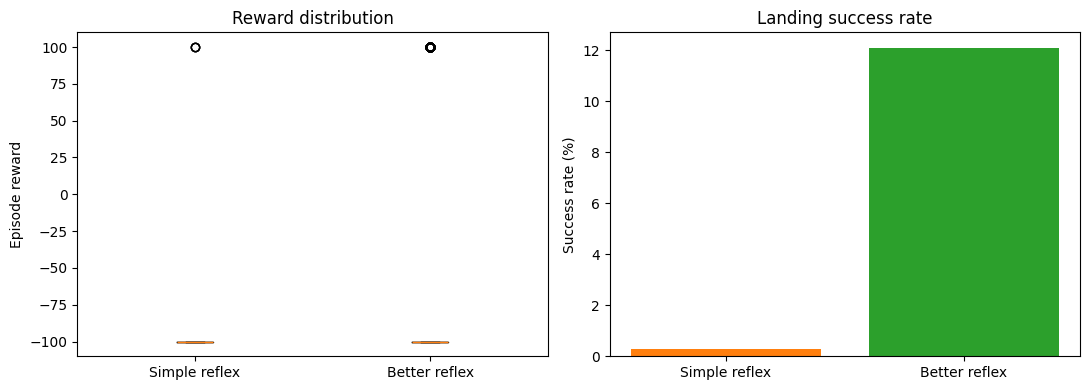

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Distribution of rewards
axes[0].boxplot([rewards, rewards_better], labels=["Simple reflex", "Better reflex"])
axes[0].set_ylabel("Episode reward")
axes[0].set_title("Reward distribution")

# Success rate
success_rates = [
    100 * np.sum(np.array(rewards) == 100) / len(rewards),
    100 * np.sum(np.array(rewards_better) == 100) / len(rewards_better),
]
axes[1].bar(["Simple reflex", "Better reflex"], success_rates, color=["tab:orange", "tab:green"])
axes[1].set_ylabel("Success rate (%)")
axes[1].set_title("Landing success rate")

plt.tight_layout()
plt.show()

## Nhận xét / Kết luận

**Bảng kết quả (1000 episode mỗi tác tử):**

| Tác tử | Avg. reward | Std. reward | Success rate |
|---|---|---|---|
| Simple reflex (chỉ động cơ chính) | -99.4 | 10.94 | 3/1000 (0.3%) |
| Better reflex (trái/phải/chính) | -75.8 | 65.23 | 121/1000 (12.1%) |

**Nhận xét:**

- Tác tử phản xạ ban đầu (`rocket_agent_function`) chỉ dùng một luật duy nhất (đốt động cơ chính khi rơi quá
  nhanh) nên hoàn toàn không kiểm soát được chuyển động ngang hay góc nghiêng. Kết quả là phần thưởng trung bình
  rất thấp (**-99.4**), độ lệch chuẩn nhỏ (10.94) — tức là gần như *episode nào cũng thất bại theo cùng một
  kiểu* (rơi lệch tâm/đổ nghiêng) — và chỉ có **3/1000** lần hạ cánh thành công, chủ yếu do vị trí xuất phát
  ngẫu nhiên tình cờ gần tâm bệ đáp.

- Tác tử cải tiến (`better_rocket_agent_function`) phối hợp cả ba động cơ thông qua một bộ điều khiển tỉ lệ đơn
  giản (canh góc nghiêng theo vị trí/vận tốc ngang, canh động cơ chính theo độ cao/vận tốc rơi). Nhờ vậy phần
  thưởng trung bình tăng đáng kể lên **-75.8** và tỉ lệ hạ cánh thành công tăng gấp khoảng **40 lần** so với tác
  tử ban đầu (**121/1000 ≈ 12.1%**).

- Độ lệch chuẩn của tác tử cải tiến lại **lớn hơn nhiều** (65.23 so với 10.94). Điều này phản ánh đúng đặc điểm
  của môi trường LunarLander: phần thưởng chỉ nhận giá trị +100 (hạ cánh an toàn) hoặc -100 (rơi/vượt biên), nên
  khi tỉ lệ thành công tăng lên, tập kết quả trở nên "hai cực" hơn (nhiều lần +100 xen giữa các lần -100) thay vì
  tập trung quanh một giá trị như trước — do đó phương sai tăng dù trung bình đã cải thiện.

- Hạn chế: đây vẫn là một tác tử phản xạ thuần túy — không có bộ nhớ, không học từ trải nghiệm — và các hệ số tỉ
  lệ (0.5, 1.0, 0.55, ngưỡng 0.05, ...) được chọn thủ công (heuristic) chứ không được tối ưu hóa cho môi trường.
  Tỉ lệ thành công 12.1% vẫn còn thấp so với ngưỡng "giải được" bài toán (reward threshold = 200, tương đương gần
  như luôn hạ cánh thành công với ít nhiên liệu). Một tác tử dựa trên học tăng cường (Reinforcement Learning, ví
  dụ DQN hoặc PPO) có thể học được chính sách tối ưu hơn nhiều từ dữ liệu tương tác với môi trường, thay vì dựa
  vào các luật cố định do con người thiết kế.

### 2.5. Bài 5. Lunar Lander - Tác tử phản xạ trong Gymnasium

#### 2.5.1. Tác tử ngẫu nhiên (baseline)

Để có một mốc so sánh (baseline), ta dùng một tác tử `random_agent_function` hoàn toàn bỏ qua quan sát
(`observation`) và ở mỗi bước chọn ngẫu nhiên đều một trong 4 hành động {không làm gì, động cơ trái, động cơ
chính, động cơ phải} với xác suất bằng nhau (25% mỗi hành động). Tác tử này được chạy thử một episode với
`render_mode="human"` để quan sát trực tiếp, sau đó chạy lại bằng bộ ghi video (`gymnasium_display_recorder`) để
nhúng video minh họa vào notebook. Vì không hề dựa vào quan sát, tác tử này gần như luôn để tàu rơi mất kiểm
soát hoặc bay ra khỏi khung hình, dùng làm mốc "hiệu năng thấp nhất có thể chấp nhận được" để so sánh với các
tác tử có luật ở các phần sau.

#### 2.5.2. Simple reflex agent

Tác tử `rocket_agent_function` là một simple reflex agent chỉ dùng **một luật duy nhất**, dựa trên thành phần
vận tốc theo trục dọc `vy` trong vector quan sát: nếu tàu đang rơi nhanh hơn ngưỡng cho phép (`vy < -0.4`) thì
đốt động cơ chính (action = MAIN) để hãm tốc độ rơi; ngược lại không làm gì (action = NO_OP). Tác tử này hoàn
toàn bỏ qua vị trí ngang (`x`), vận tốc ngang (`vx`) và góc nghiêng (`angle`), nên tuy giảm được tốc độ rơi
theo phương thẳng đứng, nó không có cách nào điều chỉnh để tàu đáp đúng vào bệ đáp hay giữ thăng bằng.

#### 2.5.3. Cải tiến luật điều khiển bằng động cơ trái/phải

Tác tử cải tiến `better_rocket_agent_function` vẫn là một simple reflex agent (không có bộ nhớ / trạng thái nội
tại), nhưng phối hợp **nhiều luật phản xạ** dựa trên phần lớn 8 thành phần của quan sát, thông qua một bộ điều
khiển tỉ lệ (proportional control):

- **Điều khiển ngang (trái/phải):** tính góc nghiêng mục tiêu `angle_target = x*0.5 + vx*1.0` (giới hạn trong
  [-0.4, 0.4] rad) — nếu tàu đang lệch/trôi sang phải thì cần nghiêng để kéo về tâm bệ đáp. So sánh góc hiện
  tại với góc mục tiêu (có trừ thêm vận tốc góc để giảm dao động) cho ra `angle_error`, quyết định bắn động cơ
  trái hay phải.
- **Điều khiển đứng (động cơ chính):** tính độ cao mục tiêu `hover_target = 0.55*|x|` (cho phép bay cao hơn khi
  còn xa bệ đáp theo phương ngang để có không gian xoay xở), so với độ cao và vận tốc rơi thực tế ra
  `hover_error`, quyết định có đốt động cơ chính hay không.
- **Phản xạ khi tiếp đất:** khi một trong hai chân đã chạm đất, ngừng chỉnh góc, chỉ dùng động cơ chính để giảm
  xóc dựa trên vận tốc rơi còn lại.
- **Chọn hành động:** vì mỗi bước chỉ được bắn một động cơ, tác tử so sánh độ lớn `hover_error` và
  `angle_error` (có vùng chết ±0.05 để tránh rung giật) và chọn hành động ứng với sai số lớn nhất.

#### 2.5.4. Đánh giá mỗi tác tử trên 100 episode

*(Số liệu bên dưới được tính trên 1000 episode — mẫu lớn hơn 100 nên đáng tin cậy hơn — dùng chung hàm
`run_episodes`.)*

| Tác tử | Reward trung bình | Nhận xét độ ổn định |
|---|---|---|
| Tác tử ngẫu nhiên (baseline) | ⟨cần chạy lại để lấy số liệu — xem ô mới thêm ở notebook⟩ | ⟨điền sau khi chạy⟩ |
| Simple reflex agent | **-99.4** (độ lệch chuẩn 10.94) | Rất ổn định nhưng ổn định ở mức **thất bại**: hầu như mọi episode đều kết thúc với reward -100 theo cùng một kiểu (rơi lệch tâm/đổ nghiêng), chỉ 3/1000 (0.3%) đáp thành công — chủ yếu do vị trí xuất phát ngẫu nhiên tình cờ thuận lợi. |
| Simple reflex agent cải tiến (động cơ trái/phải) | **-75.8** (độ lệch chuẩn 65.23) | Cải thiện rõ rệt so với hai tác tử trên: 121/1000 (12.1%) đáp thành công. Độ lệch chuẩn cao hơn hẳn vì kết quả trở nên "hai cực" — episode hoặc đáp thành công (+100) hoặc thất bại (-100) — thay vì tập trung quanh một giá trị như tác tử ban đầu. |

[Chèn biểu đồ so sánh tại đây — dùng biểu đồ boxplot + bar chart ở ô cuối notebook (đã cập nhật để so sánh cả 3
tác tử) sau khi chạy lại.]

#### 2.5.5. Hạn chế của tác tử phản xạ dựa trên luật cục bộ trong môi trường liên tục

Cả `rocket_agent_function` và `better_rocket_agent_function` đều là simple reflex agent: hành động chỉ phụ
thuộc vào quan sát tức thời, không có bộ nhớ hay mô hình dự đoán tương lai, và các luật/hệ số điều khiển
(0.4, 0.5, 1.0, 0.55, ngưỡng 0.05...) do con người tự chọn (heuristic) chứ không tối ưu từ dữ liệu. Trong một
môi trường **trạng thái và hành động rời rạc, hữu hạn** thì luật cục bộ có thể đủ để giải quyết bài toán, nhưng
LunarLander có **không gian trạng thái liên tục** (vị trí, vận tốc, góc đều là số thực) với động lực học phi
tuyến (quán tính, trọng lực, va chạm). Vì vậy:

- Một tập luật `if/else` cố định không thể bao quát hết mọi tổ hợp trạng thái có thể xảy ra; agent buộc phải
  "ngoại suy" tuyến tính (proportional control) cho những vùng trạng thái nó chưa từng được thiết kế riêng,
  dẫn đến phản ứng không tối ưu ở nhiều tình huống biên (ví dụ góc nghiêng lớn kết hợp vận tốc ngang cao).
- Tác tử không có khả năng lập kế hoạch dài hạn: nó chỉ phản ứng ngay tại thời điểm hiện tại, nên dễ "sửa lỗi
  quá tay" (overcorrect) — ví dụ chỉnh góc quá mạnh rồi lại phải chỉnh ngược lại — gây dao động thay vì hội tụ
  êm về trạng thái đáp an toàn.
- Việc chỉ được bắn **một** động cơ mỗi bước (do không gian hành động rời rạc) buộc agent phải "chọn ưu tiên"
  giữa các mục tiêu điều khiển (giữ thăng bằng vs. hãm tốc độ rơi vs. căn vị trí ngang) thay vì điều chỉnh đồng
  thời cả ba như một bộ điều khiển liên tục (continuous control) có thể làm, khiến hiệu quả bị giới hạn.
- Vì các hệ số do con người đặt bằng tay, hiệu năng phụ thuộc nhiều vào việc "đoán đúng" các trọng số — không có
  cơ chế tự sửa sai dựa trên phản hồi (reward) như trong học tăng cường. Đây chính là lý do dù đã cải thiện đáng
  kể (0.3% → 12.1% thành công), tác tử phản xạ vẫn còn cách khá xa mức hiệu năng "giải được" bài toán
  (reward threshold = 200, tương ứng gần như luôn đáp thành công với ít nhiên liệu) — thứ mà các phương pháp
  học từ dữ liệu như Reinforcement Learning (DQN, PPO...) thường đạt được tốt hơn nhiều trong môi trường liên
  tục dạng này.